# Motto

Run a small model-improvement study on image classification: train a baseline CNN, then compare it with one improvement such as data augmentation, transfer learning or a different architecture. Analyze training curves and at least 10 error cases

# Set Up

In [7]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
import json
from pathlib import Path
from IPython.display import display, Markdown

SEED = 42
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: []


# Research question:
Does data augmentation improve the generalization performance of a convolutional neural network on CIFAR-10 compared with the same CNN trained without augmentation?
# Hypothesis:
I hypothesize that a CNN trained with random horizontal flips and small translations will achieve better performance on unseen CIFAR-10 images than an identical CNN trained without these transformations.

A baseline CNN repeatedly sees the original training images. During training, it may learn useful features such as edges, textures, and object shapes, but it may also become dependent on incidental details, such as the object’s position or orientation. This can lead to overfitting, where performance on training images improves without a corresponding improvement on unseen images.

Data augmentation introduces variation by transforming training images while preserving their class labels. For example, a horizontally flipped car remains a car, and a slightly shifted airplane remains an airplane. These variations should encourage the model to recognize objects across different positions and orientations instead of relying too heavily on a particular arrangement of pixels.

The augmented model may initially learn more slowly and achieve lower training accuracy because its training examples are more varied. However, I expect it to achieve higher validation accuracy and lower validation loss at its selected checkpoint. I also expect its final test accuracy and macro-F1 score to exceed those of the baseline. Training time may increase because augmentation introduces additional computation.
To isolate the effect of augmentation, both experiments will use the same training, validation, and test splits; CNN architecture; initial CNN weights; optimizer settings; batch size; and number of epochs. The only experimental difference will be the use of horizontal flips and small translations during training. Validation and test images will remain unaugmented.

The hypothesis will be supported if the augmented model performs better on the untouched test set after each model’s checkpoint has been selected using validation loss. If its performance remains similar or becomes worse, the result may indicate that the chosen transformations provide limited benefit, remove useful information, or require a different training budget. Such explanations will be treated as possibilities rather than established causes. A single-run improvement will be interpreted cautiously because random variation can affect the results.

# Loading

In [8]:
# Load the predefined training and test sets.
(x_full, y_full), (x_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

# Convert labels from shape (N, 1) to shape (N,).
y_full = y_full.ravel()
y_test = y_test.ravel()

# The order must match CIFAR-10's numerical labels.
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

print("Dataset loaded successfully.")

Dataset loaded successfully.


# Inspection

In [9]:
print("Image array shape:", x_full.shape)
print("Label array shape:", y_full.shape)

print("\nImage data type:", x_full.dtype)
print("Label data type:", y_full.dtype)

print("\nMinimum pixel value:", x_full.min())
print("Maximum pixel value:", x_full.max())

print("\nNumber of classes:", len(np.unique(y_full)))
print("Class labels:", np.unique(y_full))

Image array shape: (50000, 32, 32, 3)
Label array shape: (50000,)

Image data type: uint8
Label data type: uint8

Minimum pixel value: 0
Maximum pixel value: 255

Number of classes: 10
Class labels: [0 1 2 3 4 5 6 7 8 9]


# Architecture

Input (32 × 32 × 3)

Conv2D: 32 filters, 3 × 3, ReLU, same padding

MaxPooling2D

Conv2D: 64 filters, 3 × 3, ReLU, same padding

MaxPooling2D

Conv2D: 128 filters, 3 × 3, ReLU, same padding Flatten

Dense: 128 units, ReLU

Dense: 10 units, softmax


# Creating Baseline

In [10]:

def build_cnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(32, 32, 3)),
        tf.keras.layers.Rescaling(1.0 / 255),

        tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
        tf.keras.layers.Flatten(),

        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

baseline = build_cnn()

# Keep these initial weights so the improved model can start from the same point.
initial_weights = baseline.get_weights()

baseline.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

# Dataset Split

In [11]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(
    x_full,
    y_full,
    test_size=0.2,
    random_state=42,
    stratify=y_full
)

print("Training images:", x_train.shape)
print("Validation images:", x_val.shape)
print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)

Training images: (40000, 32, 32, 3)
Validation images: (10000, 32, 32, 3)
Training labels: (40000,)
Validation labels: (10000,)


# Training Baseline

In [12]:
baseline_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/kaggle/working/baseline_best.keras",
    monitor="val_loss",
    save_best_only=True
)

start = time.perf_counter()

history_baseline = baseline.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=25,
    batch_size=64,
    callbacks=[baseline_checkpoint]
)

baseline_seconds = time.perf_counter() - start
print(f"Baseline training time: {baseline_seconds:.1f} seconds")

Epoch 1/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 54s 85ms/step - accuracy: 0.4705 - loss: 1.4480 - val_accuracy: 0.5961 - val_loss: 1.1349
Epoch 2/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 85ms/step - accuracy: 0.6381 - loss: 1.0256 - val_accuracy: 0.6668 - val_loss: 0.9456
Epoch 3/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 52s 83ms/step - accuracy: 0.7009 - loss: 0.8503 - val_accuracy: 0.6945 - val_loss: 0.8762
Epoch 4/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 54s 86ms/step - accuracy: 0.7459 - loss: 0.7262 - val_accuracy: 0.7133 - val_loss: 0.8316
Epoch 5/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 85ms/step - accuracy: 0.7840 - loss: 0.6219 - val_accuracy: 0.7200 - val_loss: 0.8457
Epoch 6/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 52s 82ms/step - accuracy: 0.8158 - loss: 0.5305 - val_accuracy: 0.6946 - val_loss: 0.9545
Epoch 7/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 84ms/step - accuracy: 0.8405 - loss: 0.4575 - val_accuracy: 0.6724 - val_loss: 1.0985
Epoch 8/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 52s 83ms/step - accuracy: 0.8625 - loss: 0.3993 - 

# Train Augmented Version

In [13]:

# Create the same CNN with the same starting weights.
improved_cnn = build_cnn()
improved_cnn.set_weights(initial_weights)

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal", seed=42),
    tf.keras.layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,
        seed=43
    )
], name="augmentation")

# Input images remain in their original 0–255 range.
# improved_cnn already contains the Rescaling layer.
improved = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    augmentation,
    improved_cnn
])

improved.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

improved_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/kaggle/working/improved_best.keras",
    monitor="val_loss",
    save_best_only=True
)

start = time.perf_counter()

history_improved = improved.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=25,
    batch_size=64,
    callbacks=[improved_checkpoint]
)

improved_seconds = time.perf_counter() - start

print(f"Augmented training time: {improved_seconds:.1f} seconds")

Epoch 1/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 88ms/step - accuracy: 0.4321 - loss: 1.5492 - val_accuracy: 0.5703 - val_loss: 1.1988
Epoch 2/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 85ms/step - accuracy: 0.5725 - loss: 1.1924 - val_accuracy: 0.6363 - val_loss: 1.0455
Epoch 3/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 85ms/step - accuracy: 0.6274 - loss: 1.0485 - val_accuracy: 0.6761 - val_loss: 0.9218
Epoch 4/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 54s 86ms/step - accuracy: 0.6640 - loss: 0.9521 - val_accuracy: 0.7153 - val_loss: 0.8195
Epoch 5/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 56s 89ms/step - accuracy: 0.6892 - loss: 0.8857 - val_accuracy: 0.7184 - val_loss: 0.8166
Epoch 6/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 55s 87ms/step - accuracy: 0.7080 - loss: 0.8307 - val_accuracy: 0.7304 - val_loss: 0.7795
Epoch 7/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 85ms/step - accuracy: 0.7211 - loss: 0.7955 - val_accuracy: 0.7374 - val_loss: 0.7546
Epoch 8/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 85ms/step - accuracy: 0.7361 - loss: 0.7571 - 

# Plotting

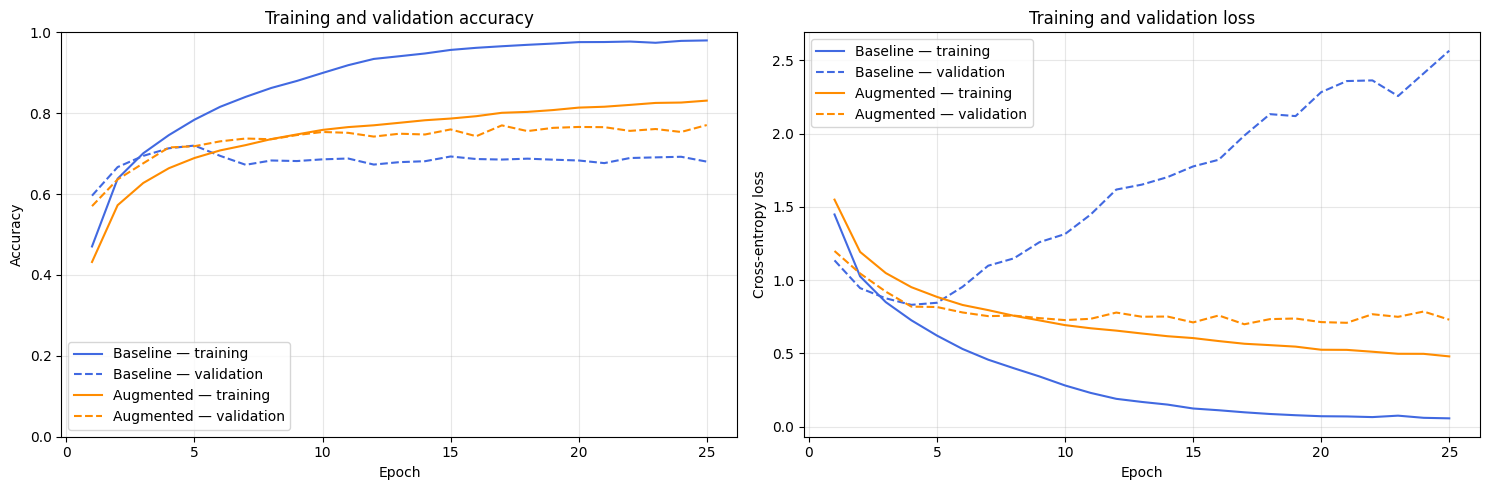

In [14]:
histories = {
    "Baseline": history_baseline.history,
    "Augmented": history_improved.history
}

colors = {
    "Baseline": "royalblue",
    "Augmented": "darkorange"
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, history in histories.items():
    epochs = np.arange(1, len(history["loss"]) + 1)

    # Accuracy: solid = training, dashed = validation
    axes[0].plot(
        epochs, history["accuracy"],
        color=colors[name],
        label=f"{name} — training"
    )
    axes[0].plot(
        epochs, history["val_accuracy"],
        color=colors[name],
        linestyle="--",
        label=f"{name} — validation"
    )

    # Loss
    axes[1].plot(
        epochs, history["loss"],
        color=colors[name],
        label=f"{name} — training"
    )
    axes[1].plot(
        epochs, history["val_loss"],
        color=colors[name],
        linestyle="--",
        label=f"{name} — validation"
    )

axes[0].set_title("Training and validation accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)

axes[1].set_title("Training and validation loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy loss")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()

plt.savefig(
    "/kaggle/working/training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Training-curve Summary

In [15]:
single_run_artifacts = {
    "baseline_history": {
        key: [float(value) for value in values]
        for key, values in history_baseline.history.items()
    },
    "augmented_history": {
        key: [float(value) for value in values]
        for key, values in history_improved.history.items()
    },
    "baseline_seconds": float(baseline_seconds),
    "improved_seconds": float(improved_seconds)
}

with open(
    "/kaggle/working/single_run_artifacts.json", "w"
) as file:
    json.dump(single_run_artifacts, file, indent=2)

print("Saved training histories and training times.")

Saved training histories and training times.


In [16]:
rows = []

for name, history in histories.items():
    best_index = int(np.argmin(history["val_loss"]))

    rows.append({
        "Model": name,
        "Selected epoch": best_index + 1,
        "Training accuracy at selected epoch (%)":
            history["accuracy"][best_index] * 100,
        "Validation accuracy at selected epoch (%)":
            history["val_accuracy"][best_index] * 100,
        "Minimum validation loss":
            history["val_loss"][best_index],
        "Peak validation accuracy (%)":
            max(history["val_accuracy"]) * 100
    })

curve_summary = pd.DataFrame(rows)

display(curve_summary.round(4))

curve_summary.to_csv(
    "/kaggle/working/training_curve_summary.csv",
    index=False
)

,Model,Selected epoch,Training accuracy at selected epoch (%),Validation accuracy at selected epoch (%),Minimum validation loss,Peak validation accuracy (%)
0,Baseline,4,74.5850,71.33,0.8316,72.00
1,Augmented,17,80.1025,76.99,0.6991,77.07


The baseline CNN showed increasing overfitting after approximately epochs 4–5. Training accuracy continued to increase, while validation accuracy remained near 70% and validation loss rose substantially. The augmented model maintained higher validation accuracy and lower validation loss. This supports the hypothesis that the chosen transformations improve generalization under the experimental settings. The augmented model’s lower training accuracy should be interpreted cautiously because it was measured on transformed images. Final comparisons use the checkpoints selected by minimum validation loss rather than the final training epoch.

# Predictions

In [17]:
# Load the augmented model selected using validation loss.
improved_best = tf.keras.models.load_model(
    "/kaggle/working/improved_best.keras"
)

probabilities = improved_best.predict(
    x_test,
    batch_size=64,
    verbose=0
)

predictions = probabilities.argmax(axis=1)
wrong_indices = np.flatnonzero(
    predictions != np.asarray(y_test).ravel()
)

print("Test images:", len(y_test))
print("Incorrect predictions:", len(wrong_indices))

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 22 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Test images: 10000
Incorrect predictions: 2337


# Metrics


Baseline: per-class test metrics


,precision,recall,f1-score,support
airplane,0.7344,0.802,0.7667,1000
automobile,0.7987,0.853,0.8250,1000
bird,0.6234,0.581,0.6014,1000
cat,0.4957,0.574,0.5320,1000
deer,0.6712,0.696,0.6834,1000
dog,0.6881,0.545,0.6083,1000
frog,0.7627,0.826,0.7931,1000
horse,0.7983,0.772,0.7850,1000
ship,0.8442,0.840,0.8421,1000
truck,0.8447,0.740,0.7889,1000



Augmented: per-class test metrics


,precision,recall,f1-score,support
airplane,0.7541,0.837,0.7934,1000
automobile,0.7971,0.931,0.8589,1000
bird,0.7711,0.603,0.6768,1000
cat,0.6356,0.511,0.5665,1000
deer,0.7737,0.725,0.7486,1000
dog,0.6746,0.680,0.6773,1000
frog,0.7578,0.848,0.8004,1000
horse,0.8021,0.835,0.8182,1000
ship,0.9051,0.830,0.8659,1000
truck,0.7747,0.863,0.8165,1000


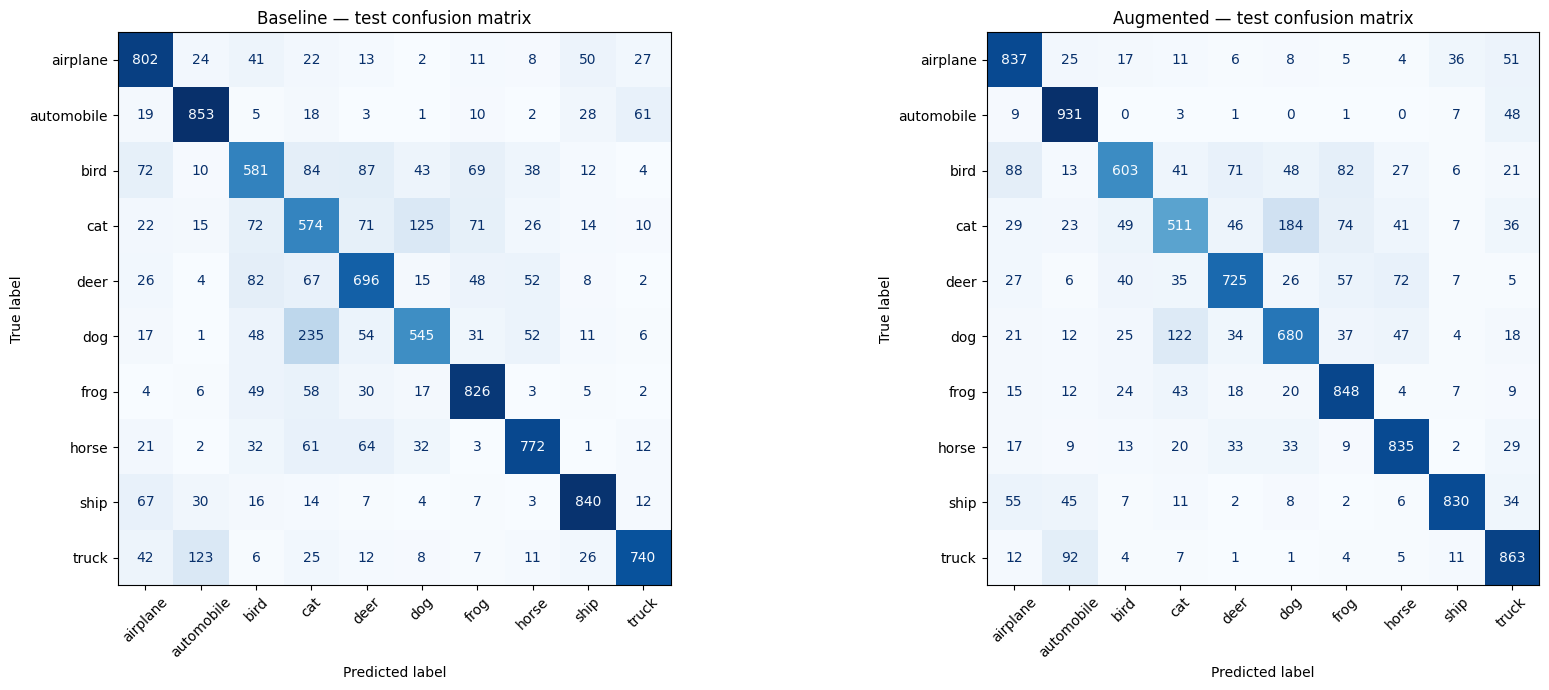

,Test accuracy (%),Test macro-F1
Model,,
Baseline,72.29,0.7226
Augmented,76.63,0.7622


Augmentation increased test accuracy by 4.34 percentage points.


In [18]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

labels = np.arange(len(class_names))
y_true = np.asarray(y_test).ravel()

models = {
    "Baseline": tf.keras.models.load_model(
        "/kaggle/working/baseline_best.keras"
    ),
    "Augmented": tf.keras.models.load_model(
        "/kaggle/working/improved_best.keras"
    )
}

# Retain predictions for your later error-case analysis.
test_probabilities = {}
test_predictions = {}
summary_rows = []

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, (name, model) in zip(axes, models.items()):
    probabilities = model.predict(
        x_test, batch_size=64, verbose=0
    )
    predictions = probabilities.argmax(axis=1)

    test_probabilities[name] = probabilities
    test_predictions[name] = predictions

    # Overall metrics
    accuracy = accuracy_score(y_true, predictions)
    macro_f1 = f1_score(
        y_true, predictions,
        labels=labels,
        average="macro",
        zero_division=0
    )

    summary_rows.append({
        "Model": name,
        "Test accuracy (%)": accuracy * 100,
        "Test macro-F1": macro_f1
    })

    # Per-class precision, recall, F1, and support
    report = classification_report(
        y_true,
        predictions,
        labels=labels,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    per_class = pd.DataFrame(report).T.loc[
        class_names,
        ["precision", "recall", "f1-score", "support"]
    ]
    per_class["support"] = per_class["support"].astype(int)

    print(f"\n{name}: per-class test metrics")
    display(per_class.round(4))

    per_class.to_csv(
        f"/kaggle/working/{name.lower()}_per_class_metrics.csv"
    )

    # Confusion matrix: rows = true classes, columns = predictions
    matrix = confusion_matrix(
        y_true, predictions, labels=labels
    )

    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=class_names
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        xticks_rotation=45,
        values_format="d"
    )

    ax.set_title(f"{name} — test confusion matrix")

plt.tight_layout()
plt.savefig(
    "/kaggle/working/confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Overall comparison
summary = pd.DataFrame(summary_rows).set_index("Model")
display(summary.round(4))

summary.to_csv("/kaggle/working/test_metrics.csv")

difference_pp = (
    summary.loc["Augmented", "Test accuracy (%)"]
    - summary.loc["Baseline", "Test accuracy (%)"]
)

if difference_pp > 0:
    print(
        f"Augmentation increased test accuracy by "
        f"{difference_pp:.2f} percentage points."
    )
elif difference_pp < 0:
    print(
        f"Augmentation decreased test accuracy by "
        f"{abs(difference_pp):.2f} percentage points."
    )
else:
    print("Both models achieved the same test accuracy.")

In [19]:
training_times = {
    "Baseline": baseline_seconds,
    "Augmented": improved_seconds
}

complete_rows = []

for name, model in models.items():
    history = histories[name]
    best_index = int(np.argmin(history["val_loss"]))

    test_metrics = model.evaluate(
        x_test,
        np.asarray(y_test).ravel(),
        batch_size=64,
        verbose=0,
        return_dict=True
    )

    complete_rows.append({
        "Model": name,
        "Selected epoch": best_index + 1,
        "Validation accuracy (%)":
            history["val_accuracy"][best_index] * 100,
        "Validation loss":
            history["val_loss"][best_index],
        "Test accuracy (%)":
            test_metrics["accuracy"] * 100,
        "Test loss":
            test_metrics["loss"],
        "Test macro-F1": f1_score(
            np.asarray(y_test).ravel(),
            test_predictions[name],
            labels=np.arange(10),
            average="macro",
            zero_division=0
        ),
        "Training time (minutes)":
            training_times[name] / 60
    })

complete_results = pd.DataFrame(
    complete_rows
).set_index("Model")

display(complete_results.round(4))

complete_results.to_csv(
    "/kaggle/working/complete_single_run_results.csv"
)

,Selected epoch,Validation accuracy (%),Validation loss,Test accuracy (%),Test loss,Test macro-F1,Training time (minutes)
Model,,,,,,,
Baseline,4,71.33,0.8316,72.29,0.8132,0.7226,21.9457
Augmented,17,76.99,0.6991,76.63,0.7145,0.7622,23.2596


# Error Analysis

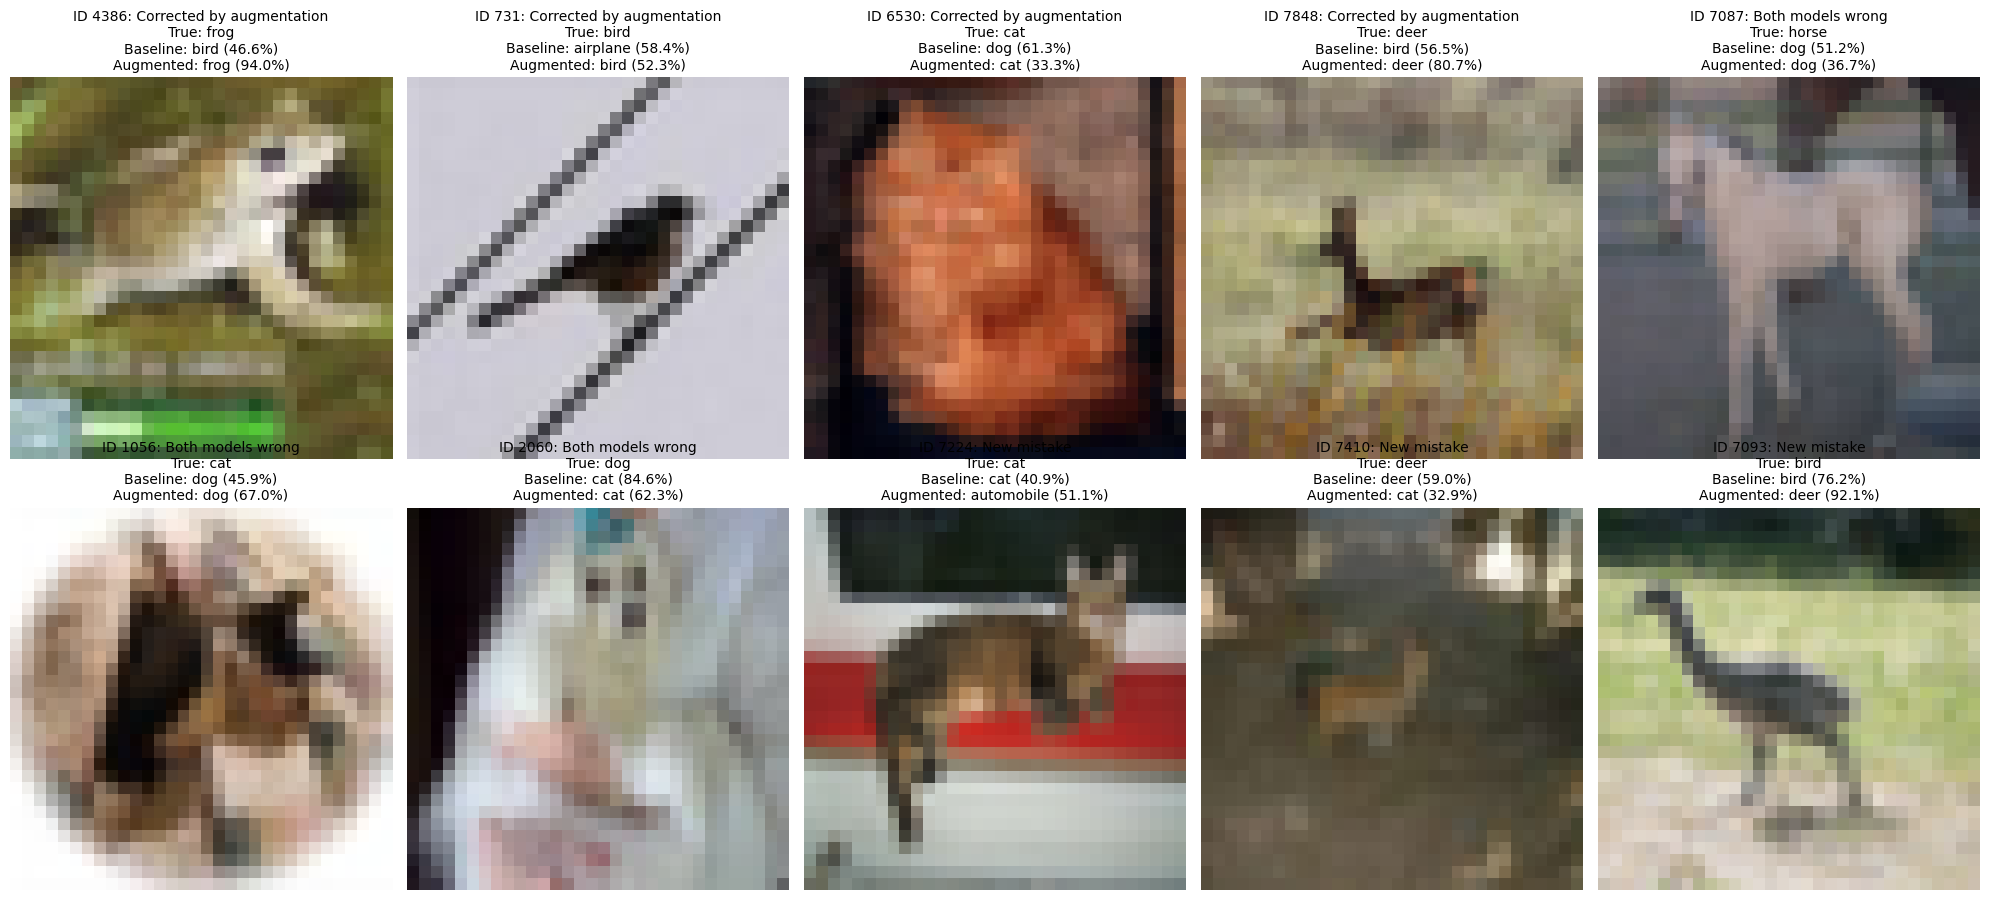

,Image ID,Category,True label,Baseline prediction,Baseline probability,Augmented prediction,Augmented probability,Visual observation,Possible explanation
0,4386,Corrected by augmentation,frog,bird,0.465569,frog,0.940075,,
1,731,Corrected by augmentation,bird,airplane,0.583503,bird,0.522827,,
2,6530,Corrected by augmentation,cat,dog,0.613046,cat,0.332721,,
3,7848,Corrected by augmentation,deer,bird,0.565051,deer,0.807067,,
4,7087,Both models wrong,horse,dog,0.511625,dog,0.367175,,
5,1056,Both models wrong,cat,dog,0.458821,dog,0.669734,,
6,2060,Both models wrong,dog,cat,0.846036,cat,0.622611,,
7,7224,New mistake,cat,cat,0.409006,automobile,0.511251,,
8,7410,New mistake,deer,deer,0.590397,cat,0.329140,,
9,7093,New mistake,bird,bird,0.761793,deer,0.920638,,


In [20]:
y_true = np.asarray(y_test).ravel()

baseline_pred = test_predictions["Baseline"]
improved_pred = test_predictions["Augmented"]

baseline_probs = test_probabilities["Baseline"]
improved_probs = test_probabilities["Augmented"]

baseline_wrong = baseline_pred != y_true
improved_wrong = improved_pred != y_true

categories = {
    "Corrected by augmentation": np.flatnonzero(
        baseline_wrong & ~improved_wrong
    ),
    "Both models wrong": np.flatnonzero(
        baseline_wrong & improved_wrong
    ),
    "New mistake": np.flatnonzero(
        ~baseline_wrong & improved_wrong
    )
}

rng = np.random.default_rng(42)
selected = []

# Sample without replacement within each category.
for (category, indices), count in zip(
    categories.items(), [4, 3, 3]
):
    chosen = rng.choice(
        indices,
        size=min(count, len(indices)),
        replace=False
    )
    selected.extend((int(i), category) for i in chosen)

# Fill any shortage from the remaining error cases.
used = {i for i, category in selected}

remaining = [
    (int(i), category)
    for category, indices in categories.items()
    for i in indices
    if int(i) not in used
]

needed = 10 - len(selected)

if needed > 0:
    if len(remaining) < needed:
        raise ValueError("Fewer than 10 distinct error cases available.")

    positions = rng.choice(
        len(remaining), size=needed, replace=False
    )
    selected.extend(remaining[int(p)] for p in positions)

fig, axes = plt.subplots(2, 5, figsize=(20, 9))
rows = []

for ax, (image_id, category) in zip(axes.ravel(), selected):
    true_label = int(y_true[image_id])
    baseline_label = int(baseline_pred[image_id])
    improved_label = int(improved_pred[image_id])

    baseline_probability = float(
        baseline_probs[image_id, baseline_label]
    )
    improved_probability = float(
        improved_probs[image_id, improved_label]
    )

    ax.imshow(x_test[image_id], interpolation="nearest")
    ax.axis("off")

    ax.set_title(
        f"ID {image_id}: {category}\n"
        f"True: {class_names[true_label]}\n"
        f"Baseline: {class_names[baseline_label]} "
        f"({baseline_probability:.1%})\n"
        f"Augmented: {class_names[improved_label]} "
        f"({improved_probability:.1%})",
        fontsize=10
    )

    rows.append({
        "Image ID": image_id,
        "Category": category,
        "True label": class_names[true_label],
        "Baseline prediction": class_names[baseline_label],
        "Baseline probability": baseline_probability,
        "Augmented prediction": class_names[improved_label],
        "Augmented probability": improved_probability,
        "Visual observation": "",
        "Possible explanation": ""
    })

plt.tight_layout()
plt.savefig(
    "/kaggle/working/error_cases.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

error_analysis = pd.DataFrame(rows)
display(error_analysis)

error_analysis.to_csv(
    "/kaggle/working/error_analysis.csv",
    index=False
)

In [21]:
training_times = {
    "Baseline": baseline_seconds,
    "Augmented": improved_seconds
}

complete_rows = []

for name, model in models.items():
    history = histories[name]
    best_index = int(np.argmin(history["val_loss"]))

    test_metrics = model.evaluate(
        x_test,
        np.asarray(y_test).ravel(),
        batch_size=64,
        verbose=0,
        return_dict=True
    )

    complete_rows.append({
        "Model": name,
        "Selected epoch": best_index + 1,
        "Validation accuracy (%)":
            history["val_accuracy"][best_index] * 100,
        "Validation loss":
            history["val_loss"][best_index],
        "Test accuracy (%)":
            test_metrics["accuracy"] * 100,
        "Test loss":
            test_metrics["loss"],
        "Test macro-F1": f1_score(
            np.asarray(y_test).ravel(),
            test_predictions[name],
            labels=np.arange(10),
            average="macro",
            zero_division=0
        ),
        "Training time (minutes)":
            training_times[name] / 60
    })

complete_results = pd.DataFrame(
    complete_rows
).set_index("Model")

display(complete_results.round(4))

complete_results.to_csv(
    "/kaggle/working/complete_single_run_results.csv"
)

,Selected epoch,Validation accuracy (%),Validation loss,Test accuracy (%),Test loss,Test macro-F1,Training time (minutes)
Model,,,,,,,
Baseline,4,71.33,0.8316,72.29,0.8132,0.7226,21.9457
Augmented,17,76.99,0.6991,76.63,0.7145,0.7622,23.2596


In [22]:
# Each pair corresponds to one row/image in the displayed grid.
# Replace every empty string after inspecting that image.
# First entry: visible observation.
# Second entry: a possible explanation, expressed cautiously.

notes = [
    ("", ""),  # Image 1: error_analysis row 0
    ("", ""),  # Image 2
    ("", ""),  # Image 3
    ("", ""),  # Image 4
    ("", ""),  # Image 5
    ("", ""),  # Image 6
    ("", ""),  # Image 7
    ("", ""),  # Image 8
    ("", ""),  # Image 9
    ("", "")   # Image 10
]

if len(notes) != len(error_analysis):
    raise ValueError("Provide one pair of notes for each selected image.")

error_analysis["Visual observation"] = [
    observation for observation, explanation in notes
]

error_analysis["Possible explanation"] = [
    explanation for observation, explanation in notes
]

completed = (
    error_analysis["Visual observation"].str.strip().ne("")
    & error_analysis["Possible explanation"].str.strip().ne("")
)

display(error_analysis)

print(
    f"Completed written analyses: "
    f"{completed.sum()}/{len(error_analysis)}"
)

error_analysis.to_csv(
    "/kaggle/working/error_analysis.csv",
    index=False
)

,Image ID,Category,True label,Baseline prediction,Baseline probability,Augmented prediction,Augmented probability,Visual observation,Possible explanation
0,4386,Corrected by augmentation,frog,bird,0.465569,frog,0.940075,,
1,731,Corrected by augmentation,bird,airplane,0.583503,bird,0.522827,,
2,6530,Corrected by augmentation,cat,dog,0.613046,cat,0.332721,,
3,7848,Corrected by augmentation,deer,bird,0.565051,deer,0.807067,,
4,7087,Both models wrong,horse,dog,0.511625,dog,0.367175,,
5,1056,Both models wrong,cat,dog,0.458821,dog,0.669734,,
6,2060,Both models wrong,dog,cat,0.846036,cat,0.622611,,
7,7224,New mistake,cat,cat,0.409006,automobile,0.511251,,
8,7410,New mistake,deer,deer,0.590397,cat,0.329140,,
9,7093,New mistake,bird,bird,0.761793,deer,0.920638,,


Completed written analyses: 0/10


Ten distinct test cases were sampled using seed 42 across corrected, shared, and newly introduced errors. This selection illustrates different outcomes and does not represent their frequency across the full test set.

# Assembling Runs

In [ ]:
from pathlib import Path
SEEDS = [42, 123, 2026]
EPOCHS = 25
BATCH_SIZE = 64

output_dir = Path("/kaggle/working/paired_runs")
output_dir.mkdir(exist_ok=True)

records = []

for seed in SEEDS:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    # Generate one set of starting CNN weights for this pair.
    initial_cnn = build_cnn()
    starting_weights = [
        weight.copy() for weight in initial_cnn.get_weights()
    ]
    del initial_cnn

    for name in ["Baseline", "Augmented"]:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)

        cnn = build_cnn()
        cnn.set_weights(starting_weights)

        if name == "Baseline":
            model = cnn
        else:
            augmentation = tf.keras.Sequential([
                tf.keras.layers.RandomFlip(
                    "horizontal", seed=seed
                ),
                tf.keras.layers.RandomTranslation(
                    height_factor=0.1,
                    width_factor=0.1,
                    seed=seed + 1
                )
            ])

            model = tf.keras.Sequential([
                tf.keras.layers.Input(shape=(32, 32, 3)),
                augmentation,
                cnn
            ])

        # Fresh optimizer for every run.
        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=0.001
            ),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        checkpoint_path = (
            output_dir / f"{name.lower()}_seed_{seed}.keras"
        )

        checkpoint = tf.keras.callbacks.ModelCheckpoint(
            str(checkpoint_path),
            monitor="val_loss",
            save_best_only=True
        )

        print(f"\nTraining {name}, seed={seed}")

        start = time.perf_counter()

        history = model.fit(
            x_train,
            y_train,
            validation_data=(x_val, y_val),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            shuffle=True,
            callbacks=[checkpoint],
            verbose=2
        )

        training_seconds = time.perf_counter() - start

        best_index = int(np.argmin(history.history["val_loss"]))

        records.append({
            "Seed": seed,
            "Model": name,
            "Selected epoch": best_index + 1,
            "Validation accuracy (%)":
                history.history["val_accuracy"][best_index] * 100,
            "Validation loss":
                history.history["val_loss"][best_index],
            "Training time (minutes)": training_seconds / 60,
            "Checkpoint": str(checkpoint_path)
        })

        with open(
            output_dir / f"{name.lower()}_seed_{seed}_history.json",
            "w"
        ) as file:
            json.dump(
                {
                    key: [float(value) for value in values]
                    for key, values in history.history.items()
                },
                file,
                indent=2
            )

        # Save progress after every completed run.
        pd.DataFrame(records).to_csv(
            output_dir / "run_results.csv",
            index=False
        )

        del model, cnn

run_results = pd.DataFrame(records)
display(run_results)

In [ ]:
from sklearn.metrics import f1_score

y_true = np.asarray(y_test).ravel()

for index, row in run_results.iterrows():
    tf.keras.backend.clear_session()

    model = tf.keras.models.load_model(row["Checkpoint"])

    metrics = model.evaluate(
        x_test, y_true,
        batch_size=64,
        verbose=0,
        return_dict=True
    )

    predictions = model.predict(
        x_test,
        batch_size=64,
        verbose=0
    ).argmax(axis=1)

    run_results.loc[index, "Test accuracy (%)"] = (
        metrics["accuracy"] * 100
    )
    run_results.loc[index, "Test loss"] = metrics["loss"]
    run_results.loc[index, "Test macro-F1"] = f1_score(
        y_true,
        predictions,
        labels=np.arange(10),
        average="macro",
        zero_division=0
    )

run_results.to_csv(
    output_dir / "run_results.csv",
    index=False
)

display(run_results.round(4))

In [ ]:
metric_columns = [
    "Validation accuracy (%)",
    "Validation loss",
    "Test accuracy (%)",
    "Test loss",
    "Test macro-F1",
    "Training time (minutes)"
]

aggregate = run_results.groupby("Model")[metric_columns].agg(
    ["mean", "std"]
)

formatted_summary = pd.DataFrame(index=aggregate.index)

for metric in metric_columns:
    formatted_summary[metric] = [
        f"{mean:.3f} ± {std:.3f}"
        for mean, std in zip(
            aggregate[(metric, "mean")],
            aggregate[(metric, "std")]
        )
    ]

display(formatted_summary)

formatted_summary.to_csv(
    output_dir / "aggregate_summary.csv"
)

# Calculate the improvement separately within each seed pair.
paired_accuracy = run_results.pivot(
    index="Seed",
    columns="Model",
    values="Test accuracy (%)"
)

paired_accuracy["Gain (percentage points)"] = (
    paired_accuracy["Augmented"]
    - paired_accuracy["Baseline"]
)

display(paired_accuracy.round(3))

gains = paired_accuracy["Gain (percentage points)"]

print(
    f"Mean paired accuracy change: "
    f"{gains.mean():+.3f} ± {gains.std(ddof=1):.3f} "
    f"percentage points"
)

paired_accuracy.to_csv(
    output_dir / "paired_accuracy_changes.csv"
)

In [ ]:
required_columns = [
    "Seed",
    "Model",
    "Test accuracy (%)",
    "Test macro-F1",
    "Training time (minutes)"
]

if run_results[required_columns].isna().any().any():
    raise ValueError(
        "Complete the repeated-run evaluations before writing the report."
    )

paired = run_results.pivot(
    index="Seed",
    columns="Model",
    values="Test accuracy (%)"
)

if paired[["Baseline", "Augmented"]].isna().any().any():
    raise ValueError("Every seed must have both model results.")

gains = paired["Augmented"] - paired["Baseline"]
number_of_pairs = len(paired)

means = run_results.groupby("Model").mean(numeric_only=True)
stds = run_results.groupby("Model").std(numeric_only=True)

direction = (
    "increased" if gains.mean() > 0
    else "decreased" if gains.mean() < 0
    else "did not change"
)

report = f"""
### Results and conclusion

The experiment compared a baseline CNN with the same CNN trained
using random horizontal flips and translations. The dataset split,
architecture, optimizer settings, batch size, and training budget
were held fixed. Within each seed pair, the CNNs used identical
initial weights. Each checkpoint was selected using minimum
validation loss.

Across **{number_of_pairs} paired seeds**, the baseline achieved
**{means.loc["Baseline", "Test accuracy (%)"]:.2f} ±
{stds.loc["Baseline", "Test accuracy (%)"]:.2f}%** test accuracy.
The augmented model achieved
**{means.loc["Augmented", "Test accuracy (%)"]:.2f} ±
{stds.loc["Augmented", "Test accuracy (%)"]:.2f}%**.

Augmentation **{direction}** mean test accuracy.
The signed mean paired change was **{gains.mean():+.2f} ±
{gains.std(ddof=1):.2f} percentage points**.
It improved accuracy in **{int((gains > 0).sum())} of
{number_of_pairs} pairs**.

Mean test macro-F1 was
**{means.loc["Baseline", "Test macro-F1"]:.4f}** for the baseline
and **{means.loc["Augmented", "Test macro-F1"]:.4f}** for the
augmented model.

Mean elapsed training time was
**{means.loc["Baseline", "Training time (minutes)"]:.2f} minutes**
for the baseline and
**{means.loc["Augmented", "Training time (minutes)"]:.2f} minutes**
for the augmented model. These timings include validation and
checkpoint saving.

### Limitations

The reported standard deviations describe variation across seeds;
they are not confidence intervals. The study uses one fixed dataset
split, one CNN architecture, and one augmentation configuration.
The selected ten error cases illustrate model behaviour but do not
estimate how frequently each visual failure pattern occurs.
"""

display(Markdown(report))